# How well do jobs and skills pay for Data Analysts.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast


from datasets import load_dataset

loaded_dataset = load_dataset("lukebarousse/data_jobs")

df = loaded_dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)


In [ ]:

df_UK = df[df['job_country'] == 'United Kingdom'].dropna(subset=['salary_year_avg'])

df_UK = df_UK.copy()

In [4]:
df_UK['salary_year_avg_gbp'] = df_UK['salary_year_avg'] * 0.7454


In [ ]:
df_UK['salary_year_avg_gbp'].describe()

In [ ]:
df_UK['salary_year_avg'].describe()

In [ ]:
df_UK[['salary_year_avg', 'salary_year_avg_gbp']].head(10)

In [ ]:
job_titles = df_UK['job_title_short'].value_counts().head(6).index.tolist()

job_titles

In [ ]:
df_UK_top6 = df_UK[df_UK['job_title_short'].isin(job_titles)]

job_order = df_UK_top6.groupby('job_title_short')['salary_year_avg_gbp'].median().sort_values(ascending=False).index

job_order

In [ ]:
df_UK_top6.groupby('job_title_short')['salary_year_avg_gbp'].describe()

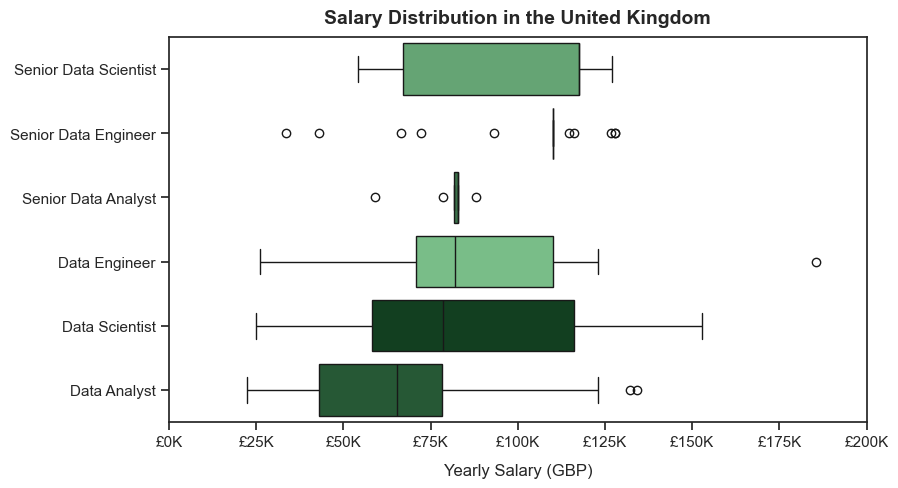

In [21]:
from matplotlib.ticker import FuncFormatter

GREEN_PALETTE = [
    "#0A461E",  # Dark green
    "#236737",  # Deep green
    "#3C8750",  # Medium green
    "#55A869",  # Light green
    "#6EC882"   # Bright green
]
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df_UK_top6,
    x='salary_year_avg_gbp',
    y='job_title_short',
    order=job_order,
    hue='job_title_short',
    palette=sns.blend_palette(GREEN_PALETTE, n_colors=len(job_order)),
    dodge=False,
    legend=False
)
sns.set_theme(style="ticks")

plt.title('Salary Distribution in the United Kingdom', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('Yearly Salary (GBP)', fontsize=12, labelpad=10)
plt.ylabel('')
plt.xlim(0, 200000)
ticks_x = plt.FuncFormatter(lambda x, pos: f'£{int(x/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)

plt.show()

In [ ]:
# Investigate Median Salary Vs Skill for Data Analysts in the United Kingdom.


df_DA_UK = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United Kingdom')].copy()

df_DA_UK['salary_year_avg_gbp'] = df_DA_UK['salary_year_avg'] * 0.7454

df_DA_UK = df_DA_UK.dropna(subset=['salary_year_avg_gbp'])

df_DA_UK = df_DA_UK.explode('job_skills')

df_DA_UK[['job_skills', 'salary_year_avg_gbp']].head(5)

In [ ]:
df_DA_top_pay = df_DA_UK.groupby('job_skills')['salary_year_avg_gbp'].agg(['count', 'median']).sort_values(by='median', ascending=False)

df_DA_top_pay = df_DA_top_pay.head(10)
df_DA_top_pay

In [ ]:
df_DA_UK_Skills = df_DA_UK.groupby('job_skills')['salary_year_avg_gbp'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_UK_Skills = df_DA_UK_Skills.head(10).sort_values(by='median', ascending=False)

df_DA_UK_Skills

In [ ]:
# visualize 1. Top 10 highest paying skills for Data Analysts in the United Kingdom.

#           2. top 10 most in_demand skills for Data Analysts in the United Kingdom.

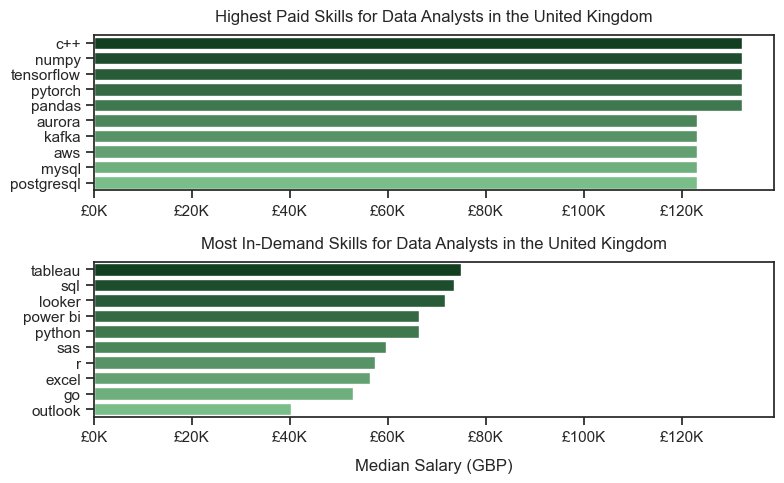

In [23]:
sns.set_theme(style="ticks")

GREEN_PALETTE = [
    "#0A461E",  # Dark green
    "#236737",  # Deep green
    "#3C8750",  # Medium green
    "#55A869",  # Light green
    "#6EC882"   # Bright green
]

fig, ax = plt.subplots(2, 1 , figsize=(8, 5))

# Highest paid skills
sns.barplot(
    data=df_DA_top_pay,
    x='median',
    y=df_DA_top_pay.index,
    hue=df_DA_top_pay.index,
    palette=sns.blend_palette(
        GREEN_PALETTE, n_colors=len(df_DA_top_pay)
    ),
    dodge=False,
    legend=False,
    ax=ax[0]
)

ax[0].set_title(
    'Highest Paid Skills for Data Analysts in the United Kingdom',
    pad=10
)
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x / 1000:.0f}K')
)


# Most in-demand skills
sns.barplot(
    data=df_DA_UK_Skills,
    x='median',
    y=df_DA_UK_Skills.index,
    hue=df_DA_UK_Skills.index,
    palette=sns.blend_palette(
        GREEN_PALETTE, n_colors=len(df_DA_UK_Skills)
    ),
    dodge=False,
    legend=False,
    ax=ax[1]
)

ax[1].set_title(
    'Most In-Demand Skills for Data Analysts in the United Kingdom',
    pad=10
)
ax[1].set_xlabel('Median Salary (GBP)', fontsize=12, labelpad=10)
ax[1].set_ylabel('')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'£{x / 1000:.0f}K')
)

plt.tight_layout()
plt.show()